# AVX-DS-CAP — Phase A: Analytical Build
## E-Commerce Customer Intelligence and Sales Forecasting System

This notebook follows the Phase A requirements in the AVX-DS-CAP project brief:
1. Understand and integrate related Olist tables, with documented joins and row-count checks.
2. Audit and clean data quality issues.
3. Create at least eight meaningful EDA visualizations and interpret them using actual results.
4. Engineer at least eight business features.
5. Segment customers with RFM and K-Means; test K=2 through K=6 with elbow and silhouette analysis.
6. Define a low-review prediction task, compare a baseline and at least three models, and avoid target leakage.
7. Use stratified five-fold cross-validation and hyperparameter tuning.
8. Analyze monthly sales, hold out a test period, and report forecast MAE/RMSE.


**Target definition:** low review means review score 1 or 2. The prediction point is after delivery and before the review is submitted. Review-derived fields are never model predictors. This is a retrospective prediction, not a causal analysis.

**Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).

## 1. Install libraries


In [1]:
%pip install -q kaggle pandas numpy matplotlib seaborn scikit-learn statsmodels joblib reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 21.9 MB/s eta 0:00:00


## 2. Download the Olist dataset


In [2]:
from google.colab import files
from pathlib import Path
import os, shutil, subprocess

uploaded = files.upload()  # Select kaggle.json
if "kaggle.json" not in uploaded:
    raise FileNotFoundError("Please upload the Kaggle API file named kaggle.json.")

kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)
token_path = kaggle_dir / "kaggle.json"
shutil.move("/content/kaggle.json", str(token_path))
os.chmod(token_path, 0o600)

DATA_DIR = Path("/content/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
result = subprocess.run(
    ["kaggle", "datasets", "download", "-d", "olistbr/brazilian-ecommerce", "-p", str(DATA_DIR), "--unzip"],
    capture_output=True, text=True
)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Kaggle download failed. Check your API token and dataset access.")
print(result.stdout)
print("Downloaded CSVs:")
for p in sorted(DATA_DIR.glob("*.csv")):
    print(p.name, f"{p.stat().st_size / 1024:.1f} KB")

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
License(s): CC-BY-NC-SA-4.0


Downloaded CSVs:
olist_customers_dataset.csv 8822.2 KB
olist_geolocation_dataset.csv 59837.8 KB
olist_order_items_dataset.csv 15076.8 KB
olist_order_payments_dataset.csv 5641.7 KB
olist_order_reviews_dataset.csv 14113.0 KB
olist_orders_dataset.csv 17241.1 KB
olist_products_dataset.csv 2323.7 KB
olist_sellers_dataset.csv 170.6 KB
product_category_name_translation.csv 2.6 KB


## 3. Imports and output folder

In [3]:
import json, warnings, joblib, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay, mean_absolute_error,
                             mean_squared_error, silhouette_score)
from sklearn.cluster import KMeans
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
OUTPUT_DIR = Path("/content/AVX_DS_CAP_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output directory:", OUTPUT_DIR)

Output directory: /content/AVX_DS_CAP_outputs


## 4. Load all source tables separately

In [4]:
table_files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}
tables = {}
for name, filename in table_files.items():
    path = DATA_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"Missing {filename}; check the extracted Kaggle dataset.")
    tables[name] = pd.read_csv(path)

print("Source table dimensions")
for name, frame in tables.items():
    print(f"{name:24s} {len(frame):>9,} rows x {len(frame.columns):>3} columns")

Source table dimensions
customers                   99,441 rows x   5 columns
geolocation              1,000,163 rows x   5 columns
order_items                112,650 rows x   7 columns
payments                   103,886 rows x   5 columns
reviews                     99,224 rows x   7 columns
orders                      99,441 rows x   8 columns
products                    32,951 rows x   9 columns
sellers                      3,095 rows x   4 columns
category_translation            71 rows x   2 columns


## 5. Initial data-quality audit
This is the before-cleaning audit. Missing values may be legitimate, such as delivery dates missing for canceled or undelivered orders.

In [5]:
quality_before = pd.DataFrame([{
    "table": name, "rows": len(frame), "columns": len(frame.columns),
    "duplicate_rows": int(frame.duplicated().sum()),
    "missing_cells": int(frame.isna().sum().sum()),
    "missing_percent": round(frame.isna().sum().sum() / max(frame.size, 1) * 100, 3)
} for name, frame in tables.items()])
display(quality_before)
quality_before.to_csv(OUTPUT_DIR / "data_quality_before.csv", index=False)
for name, frame in tables.items():
    print("\n", name, "— missing values by column")
    display(pd.DataFrame({"dtype": frame.dtypes.astype(str), "missing": frame.isna().sum()})
            .sort_values("missing", ascending=False).head(12))

,table,rows,columns,duplicate_rows,missing_cells,missing_percent
0,customers,99441,5,0,0,0.000
1,geolocation,1000163,5,261831,0,0.000
2,order_items,112650,7,0,0,0.000
3,payments,103886,5,0,0,0.000
4,reviews,99224,7,0,145903,21.006
5,orders,99441,8,0,4908,0.617
6,products,32951,9,0,2448,0.825
7,sellers,3095,4,0,0,0.000
8,category_translation,71,2,0,0,0.000



 customers — missing values by column


,dtype,missing
customer_id,object,0
customer_unique_id,object,0
customer_zip_code_prefix,int64,0
customer_city,object,0
customer_state,object,0



 geolocation — missing values by column


,dtype,missing
geolocation_zip_code_prefix,int64,0
geolocation_lat,float64,0
geolocation_lng,float64,0
geolocation_city,object,0
geolocation_state,object,0


...

,dtype,missing
product_category_name,object,610
product_description_lenght,float64,610
product_name_lenght,float64,610
product_photos_qty,float64,610
product_weight_g,float64,2
product_height_cm,float64,2
product_length_cm,float64,2
product_width_cm,float64,2
product_id,object,0



 sellers — missing values by column


,dtype,missing
seller_id,object,0
seller_zip_code_prefix,int64,0
seller_city,object,0
seller_state,object,0



 category_translation — missing values by column


,dtype,missing
product_category_name,object,0
product_category_name_english,object,0


## 6. Data model and relationship checks
The main analytical grain is one row per order. `order_items`, `payments`, and `reviews` may contain multiple rows per order, so they are aggregated before joining. The geolocation table is not directly joined because several coordinates can exist per ZIP prefix, which could multiply rows.

| Relationship | Key | Expected cardinality |
|---|---|---|
| orders → customers | `customer_id` | many orders to one customer record |
| order items → orders | `order_id` | many items to one order |
| payments → orders | `order_id` | many payments to one order |
| reviews → orders | `order_id` | potentially multiple review records to one order |
| order items → products | `product_id` | many item rows to one product |
| order items → sellers | `seller_id` | many item rows to one seller |
| products → translation | `product_category_name` | many products to one translated category |

In [6]:
orders = tables["orders"].drop_duplicates().copy()
customers = tables["customers"].drop_duplicates().copy()
items = tables["order_items"].drop_duplicates().copy()
payments = tables["payments"].drop_duplicates().copy()
reviews = tables["reviews"].drop_duplicates().copy()
products = tables["products"].drop_duplicates().copy()
sellers = tables["sellers"].drop_duplicates().copy()
translation = tables["category_translation"].drop_duplicates().copy()

for col in ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_estimated_delivery_date"]:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")
for col in ["review_creation_date", "review_answer_timestamp"]:
    reviews[col] = pd.to_datetime(reviews[col], errors="coerce")

relationship_checks = pd.DataFrame([
    {"check": "orders.order_id unique", "passed": orders["order_id"].is_unique},
    {"check": "customers.customer_id unique", "passed": customers["customer_id"].is_unique},
    {"check": "products.product_id unique", "passed": products["product_id"].is_unique},
    {"check": "sellers.seller_id unique", "passed": sellers["seller_id"].is_unique},
    {"check": "item order_id non-null", "passed": items["order_id"].notna().all()},
    {"check": "payment order_id non-null", "passed": payments["order_id"].notna().all()},
    {"check": "review order_id non-null", "passed": reviews["order_id"].notna().all()}
])
display(relationship_checks)
relationship_checks.to_csv(OUTPUT_DIR / "relationship_checks.csv", index=False)
print("Orders with multiple item rows:", int(items["order_id"].value_counts().gt(1).sum()))
print("Orders with multiple payment rows:", int(payments["order_id"].value_counts().gt(1).sum()))
print("Orders with multiple review rows:", int(reviews["order_id"].value_counts().gt(1).sum()))

# Record duplicate removal for documentation.
duplicate_summary = []
for name, original in tables.items():
    cleaned = original.drop_duplicates()
    duplicate_summary.append({"table": name, "rows_before": len(original),
                              "exact_duplicates_removed": len(original)-len(cleaned), "rows_after": len(cleaned)})
pd.DataFrame(duplicate_summary).to_csv(OUTPUT_DIR / "duplicate_cleaning_summary.csv", index=False)

,check,passed
0,orders.order_id unique,True
1,customers.customer_id unique,True
2,products.product_id unique,True
3,sellers.seller_id unique,True
4,item order_id non-null,True
5,payment order_id non-null,True
6,review order_id non-null,True


Orders with multiple item rows: 9803
Orders with multiple payment rows: 2961
Orders with multiple review rows: 547


## 7. Enrich item rows, then aggregate to one row per order
By joining product/seller details to item rows using many-to-one validation, aggregate items by order, and independently aggregate payment and review records by order. This is the main protection against accidental row multiplication.

In [7]:
for col in ["price", "freight_value"]:
    items[col] = pd.to_numeric(items[col], errors="coerce")
payments["payment_value"] = pd.to_numeric(payments["payment_value"], errors="coerce")
payments["payment_installments"] = pd.to_numeric(payments["payment_installments"], errors="coerce")
reviews["review_score"] = pd.to_numeric(reviews["review_score"], errors="coerce")

def safe_mode(series):
    vals = series.dropna()
    if vals.empty:
        return np.nan
    modes = vals.mode()
    return modes.iloc[0] if len(modes) else vals.iloc[0]

items_enriched = items.merge(
    products[["product_id", "product_category_name", "product_weight_g", "product_length_cm",
              "product_height_cm", "product_width_cm"]],
    on="product_id", how="left", validate="many_to_one"
).merge(
    sellers[["seller_id", "seller_state", "seller_city"]],
    on="seller_id", how="left", validate="many_to_one"
)
items_enriched = items_enriched.merge(
    translation.drop_duplicates("product_category_name"),
    on="product_category_name", how="left", validate="many_to_one"
)
if "product_category_name_english" in items_enriched:
    items_enriched["category_for_analysis"] = items_enriched["product_category_name_english"].fillna(items_enriched["product_category_name"])
else:
    items_enriched["category_for_analysis"] = items_enriched["product_category_name"]

item_agg = items_enriched.groupby("order_id").agg(
    item_count=("order_item_id", "count"), item_sales=("price", "sum"),
    total_freight=("freight_value", "sum"), unique_products=("product_id", "nunique"),
    unique_sellers=("seller_id", "nunique"), unique_categories=("category_for_analysis", "nunique"),
    main_category=("category_for_analysis", safe_mode), seller_state_mode=("seller_state", safe_mode),
    avg_product_weight_g=("product_weight_g", "mean"), avg_product_length_cm=("product_length_cm", "mean"),
    avg_product_height_cm=("product_height_cm", "mean"), avg_product_width_cm=("product_width_cm", "mean")
).reset_index()

payment_agg = payments.groupby("order_id").agg(
    payment_total=("payment_value", "sum"), payment_type_mode=("payment_type", safe_mode),
    payment_installments_max=("payment_installments", "max"), payment_records=("payment_type", "size")
).reset_index()
review_agg = reviews.groupby("order_id").agg(
    review_score=("review_score", "mean"), review_records=("review_score", "count")
).reset_index()

print("Unique order IDs — items:", item_agg["order_id"].nunique())
print("Unique order IDs — payments:", payment_agg["order_id"].nunique())
print("Unique order IDs — reviews:", review_agg["order_id"].nunique())

Unique order IDs — items: 98666
Unique order IDs — payments: 99440
Unique order IDs — reviews: 98673


## 8. Build and validate the order-level analytical table
Start from orders and left-join the customer record and the aggregated item, payment, and review tables. The number of rows should not change because each joined table has at most one row per order.

In [8]:
orders_base = orders.merge(
    customers[["customer_id", "customer_unique_id", "customer_city", "customer_state", "customer_zip_code_prefix"]],
    on="customer_id", how="left", validate="many_to_one"
)
join_audit = [{"step": "orders + customers", "rows_before": len(orders), "rows_after": len(orders_base)}]
for right, label in [(item_agg, "item aggregate"), (payment_agg, "payment aggregate"), (review_agg, "review aggregate")]:
    before = len(orders_base)
    orders_base = orders_base.merge(right, on="order_id", how="left", validate="one_to_one")
    join_audit.append({"step": label, "rows_before": before, "rows_after": len(orders_base)})
join_audit = pd.DataFrame(join_audit)
display(join_audit)
join_audit.to_csv(OUTPUT_DIR / "join_audit.csv", index=False)
assert orders_base["order_id"].is_unique, "Duplicate order IDs after joining."
assert len(orders_base) == len(orders), "Row count changed unexpectedly after joining."
print("Order-level table shape:", orders_base.shape)
display(orders_base.head())

,step,rows_before,rows_after
0,orders + customers,99441,99441
1,item aggregate,99441,99441
2,payment aggregate,99441,99441
3,review aggregate,99441,99441


Order-level table shape: (99441, 30)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state,customer_zip_code_prefix,item_count,item_sales,total_freight,unique_products,unique_sellers,unique_categories,main_category,seller_state_mode,avg_product_weight_g,avg_product_length_cm,avg_product_height_cm,avg_product_width_cm,payment_total,payment_type_mode,payment_installments_max,payment_records,review_score,review_records
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,3149,1.0,29.99,8.72,1.0,1.0,1.0,housewares,SP,500.0,19.0,8.0,13.0,38.71,voucher,1.0,3.0,4.0,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,barreiras,BA,47813,1.0,118.70,22.76,1.0,1.0,1.0,perfumery,SP,400.0,19.0,13.0,19.0,141.46,boleto,1.0,1.0,4.0,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,75265,1.0,159.90,19.22,1.0,1.0,1.0,auto,SP,420.0,24.0,19.0,21.0,179.12,credit_card,3.0,1.0,5.0,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN,59296,1.0,45.00,27.20,1.0,1.0,1.0,pet_shop,MG,450.0,30.0,10.0,20.0,72.20,credit_card,1.0,1.0,5.0,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,9195,1.0,19.90,8.72,1.0,1.0,1.0,stationery,SP,250.0,51.0,15.0,15.0,28.62,credit_card,1.0,1.0,5.0,1.0


## 9. Clean data and engineer business features
Remove records without purchase timestamps because time-based analysis requires them. Negative totals are treated as invalid/missing and reported. Missing delivery dates are retained for descriptive analysis. The model pipeline later imputes missing predictor values using training data only.

Engineered features include delivery duration, estimated delivery duration, delivery delay, calendar features, average item price, freight share, payment-to-sales ratio, multi-item and multi-seller flags, and customer purchase history computed using only earlier orders.

In [9]:
df = orders_base.copy()
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")
for col in ["item_sales", "total_freight", "payment_total", "review_score"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

before_rows = len(df)
df = df[df["order_purchase_timestamp"].notna()].copy()
print("Rows removed due to missing purchase timestamp:", before_rows - len(df))
for col in ["item_sales", "total_freight", "payment_total"]:
    print("Negative values in", col, ":", int((df[col] < 0).sum()))
    df.loc[df[col] < 0, col] = np.nan

df["delivery_days"] = (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.total_seconds()/86400
df["estimated_delivery_days"] = (df["order_estimated_delivery_date"] - df["order_purchase_timestamp"]).dt.total_seconds()/86400
df["delivery_delay_days"] = (df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]).dt.total_seconds()/86400
df["purchase_year"] = df["order_purchase_timestamp"].dt.year
df["purchase_month"] = df["order_purchase_timestamp"].dt.month
df["purchase_dayofweek"] = df["order_purchase_timestamp"].dt.dayofweek
df["purchase_hour"] = df["order_purchase_timestamp"].dt.hour
df["purchase_month_period"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["average_item_price"] = df["item_sales"] / df["item_count"].replace(0, np.nan)
df["freight_share"] = df["total_freight"] / df["item_sales"].replace(0, np.nan)
df["payment_to_item_sales_ratio"] = df["payment_total"] / df["item_sales"].replace(0, np.nan)
df["has_multiple_items"] = (df["item_count"].fillna(0) > 1).astype(int)
df["has_multiple_sellers"] = (df["unique_sellers"].fillna(0) > 1).astype(int)
df["delivery_late"] = np.where(df["delivery_delay_days"].notna(), (df["delivery_delay_days" ] > 0).astype(int), np.nan)

# Prior-order features are calculated from earlier orders only, never from future orders.
df = df.sort_values(["customer_unique_id", "order_purchase_timestamp", "order_id"]).copy()
df["customer_prior_order_count"] = df.groupby("customer_unique_id").cumcount()
df["customer_prior_item_sales"] = df.groupby("customer_unique_id")["item_sales"].transform(lambda s: s.shift().fillna(0).cumsum())
first_prior = df.groupby("customer_unique_id")["order_purchase_timestamp"].transform(lambda s: s.shift().ffill())
df["customer_tenure_days_at_order"] = (df["order_purchase_timestamp"] - first_prior).dt.total_seconds()/86400

engineered_features = ["delivery_days", "estimated_delivery_days", "delivery_delay_days", "purchase_year",
    "purchase_month", "purchase_dayofweek", "purchase_hour", "average_item_price", "freight_share",
    "payment_to_item_sales_ratio", "has_multiple_items", "has_multiple_sellers", "delivery_late",
    "customer_prior_order_count", "customer_prior_item_sales", "customer_tenure_days_at_order"]
print("Engineered feature count:", len(engineered_features))
print(engineered_features)
display(df[engineered_features].describe().T)

Rows removed due to missing purchase timestamp: 0
Negative values in item_sales : 0
Negative values in total_freight : 0
Negative values in payment_total : 0
Engineered feature count: 16
['delivery_days', 'estimated_delivery_days', 'delivery_delay_days', 'purchase_year', 'purchase_month', 'purchase_dayofweek', 'purchase_hour', 'average_item_price', 'freight_share', 'payment_to_item_sales_ratio', 'has_multiple_items', 'has_multiple_sellers', 'delivery_late', 'customer_prior_order_count', 'customer_prior_item_sales', 'customer_tenure_days_at_order']


,count,mean,std,min,25%,50%,75%,max
delivery_days,96476.0,12.558702,9.546530,0.533414,6.766403,10.217755,15.720327,209.628611
estimated_delivery_days,99441.0,23.767650,8.832371,1.648993,18.331690,23.240370,28.424861,155.135463
delivery_delay_days,96476.0,-11.179120,10.186113,-146.016123,-16.244384,-11.948941,-6.390000,188.975081
purchase_year,99441.0,2017.539838,0.505007,2016.000000,2017.000000,2018.000000,2018.000000,2018.000000
purchase_month,99441.0,6.032220,3.232999,1.000000,3.000000,6.000000,8.000000,12.000000
purchase_dayofweek,99441.0,2.755735,1.966495,0.000000,1.000000,3.000000,4.000000,6.000000
purchase_hour,99441.0,14.770829,5.326800,0.000000,11.000000,15.000000,19.000000,23.000000
average_item_price,98666.0,125.919255,190.985636,0.850000,41.990000,79.000000,139.900000,6735.000000
freight_share,98666.0,0.308389,0.314762,0.000000,0.131864,0.224374,0.380191,21.447059
payment_to_item_sales_ratio,98665.0,1.308719,0.314990,0.976283,1.131938,1.224374,1.380845,22.447059


## 10. Post-cleaning quality checks and save the clean analytical dataset

In [10]:
quality_after = pd.DataFrame([{
    "table": "order_level_analytical", "rows": len(df), "columns": len(df.columns),
    "duplicate_rows": int(df.duplicated().sum()), "duplicate_order_ids": int(df["order_id"].duplicated().sum()),
    "missing_cells": int(df.isna().sum().sum()),
    "missing_percent": round(df.isna().sum().sum()/max(df.size, 1)*100, 3)
}])
display(quality_after)
quality_after.to_csv(OUTPUT_DIR / "data_quality_after.csv", index=False)
df.to_csv(OUTPUT_DIR / "clean_analytical_dataset.csv", index=False)
print("Saved clean_analytical_dataset.csv")

,table,rows,columns,duplicate_rows,duplicate_order_ids,missing_cells,missing_percent
0,order_level_analytical,99441,47,0,0,124518,2.664


Saved clean_analytical_dataset.csv


# 11. Exploratory data analysis


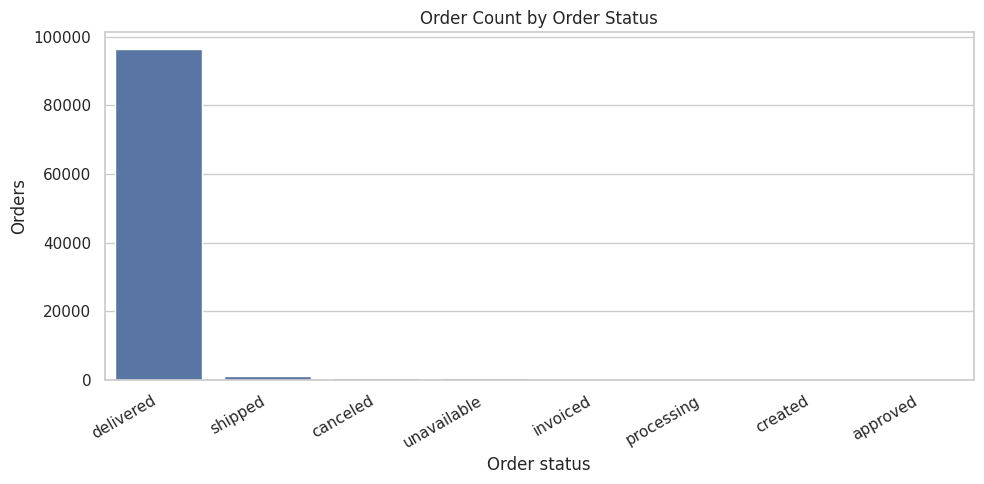

,orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [11]:
# EDA 1 — order status counts
counts = df["order_status"].value_counts(dropna=False)
plt.figure(figsize=(10,5)); sns.barplot(x=counts.index, y=counts.values)
plt.title("Order Count by Order Status"); plt.xlabel("Order status"); plt.ylabel("Orders")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.savefig(OUTPUT_DIR/"eda_01_order_status.png", dpi=150); plt.show()
display(counts.rename("orders").to_frame())

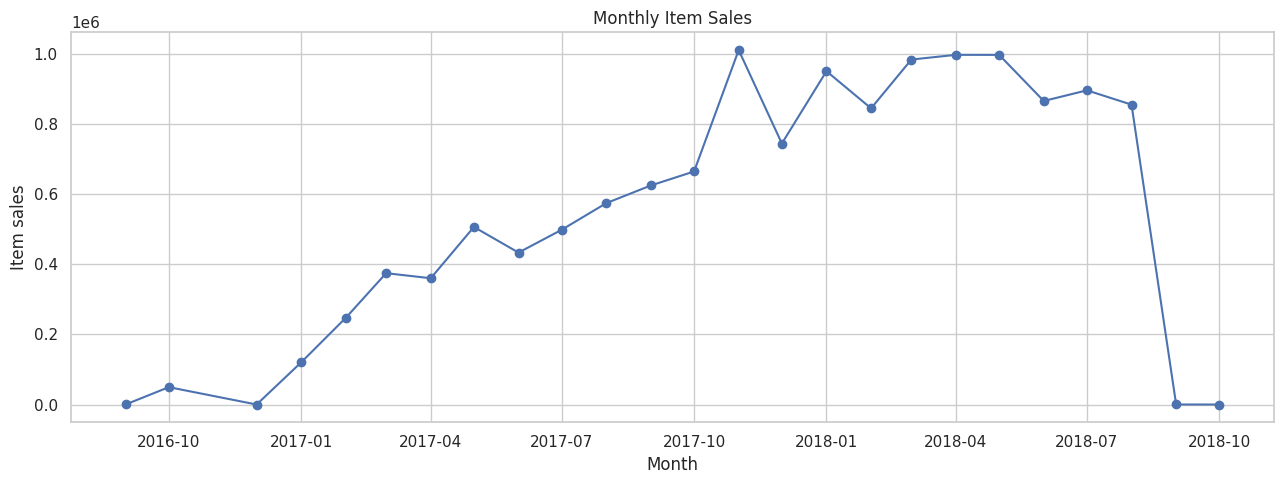

,item_sales
month,
2017-11-01,1010271.37
2017-12-01,743914.17
2018-01-01,950030.36
2018-02-01,844178.71
2018-03-01,983213.44
2018-04-01,996647.75
2018-05-01,996517.68
2018-06-01,865124.31
2018-07-01,895507.22


In [12]:
# EDA 2 — monthly item sales
monthly_sales = df.assign(month=df["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()).groupby("month")["item_sales"].sum().sort_index()
plt.figure(figsize=(13,5)); plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Item Sales"); plt.xlabel("Month"); plt.ylabel("Item sales")
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"eda_02_monthly_sales.png", dpi=150); plt.show()
display(monthly_sales.tail(12).to_frame("item_sales"))

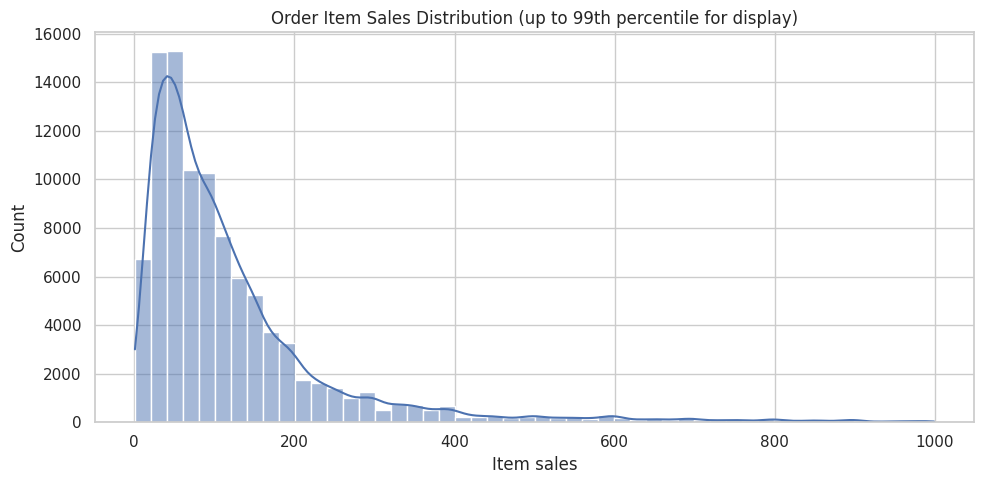

Median item sales: 86.9 | 99th percentile: 998.9


In [13]:
# EDA 3 — item sales distribution; only the display is clipped at the 99th percentile
sales = df["item_sales"].dropna(); upper = sales.quantile(.99)
plt.figure(figsize=(10,5)); sns.histplot(sales[sales <= upper], bins=50, kde=True)
plt.title("Order Item Sales Distribution (up to 99th percentile for display)"); plt.xlabel("Item sales")
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"eda_03_sales_distribution.png", dpi=150); plt.show()
print("Median item sales:", sales.median(), "| 99th percentile:", upper)

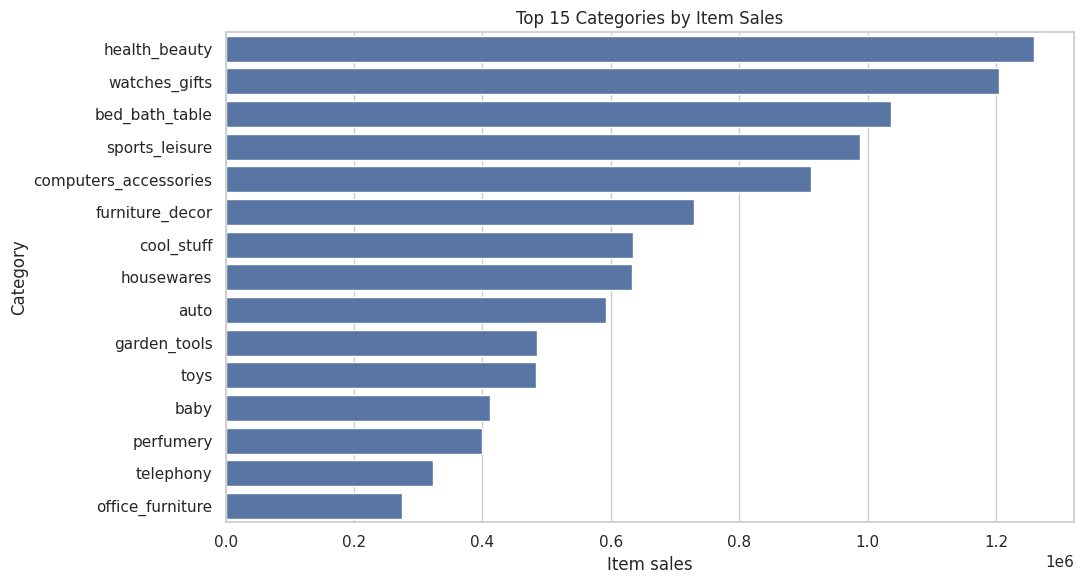

,item_sales
category_for_analysis,
health_beauty,1258681.34
watches_gifts,1205005.68
bed_bath_table,1036988.68
sports_leisure,988048.97
computers_accessories,911954.32
furniture_decor,729762.49
cool_stuff,635290.85
housewares,632248.66
auto,592720.11


In [14]:
# EDA 4 — top product categories by sales
category_sales = items_enriched.groupby("category_for_analysis", dropna=False)["price"].sum().sort_values(ascending=False).head(15)
plt.figure(figsize=(11,6)); sns.barplot(x=category_sales.values, y=category_sales.index)
plt.title("Top 15 Categories by Item Sales"); plt.xlabel("Item sales"); plt.ylabel("Category")
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"eda_04_top_categories.png", dpi=150); plt.show()
display(category_sales.rename("item_sales").to_frame())

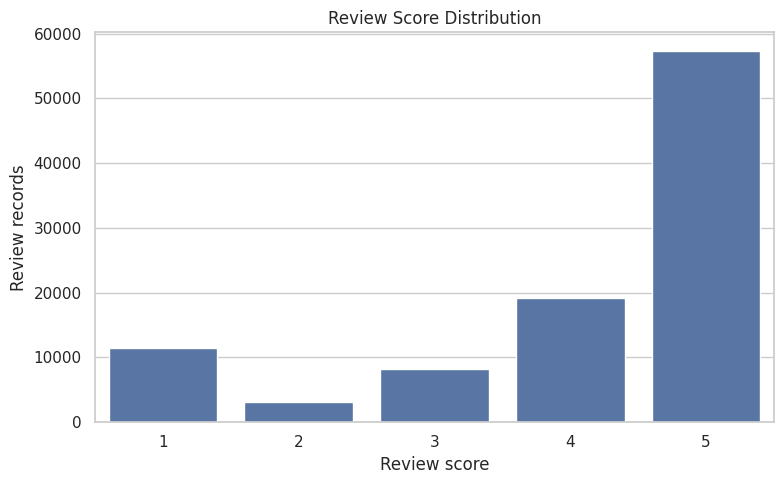

,review_records
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


In [15]:
# EDA 5 — review-score distribution
review_dist = reviews["review_score"].value_counts().sort_index()
plt.figure(figsize=(8,5)); sns.barplot(x=review_dist.index.astype(str), y=review_dist.values)
plt.title("Review Score Distribution"); plt.xlabel("Review score"); plt.ylabel("Review records")
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"eda_05_review_scores.png", dpi=150); plt.show()
display(review_dist.rename("review_records").to_frame())

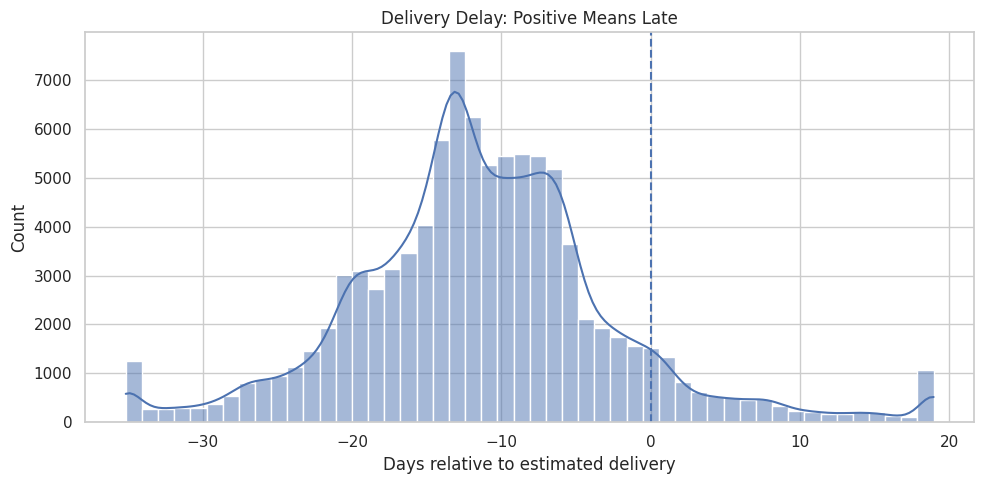

Median delay days: -11.948940972222221 | Late share: 8.11 %


In [16]:
# EDA 6 — delivery delay distribution (plot clips display to 1st–99th percentiles)
delays = df["delivery_delay_days"].dropna(); delays_plot = delays.clip(delays.quantile(.01), delays.quantile(.99))
plt.figure(figsize=(10,5)); sns.histplot(delays_plot, bins=50, kde=True); plt.axvline(0, linestyle="--")
plt.title("Delivery Delay: Positive Means Late"); plt.xlabel("Days relative to estimated delivery")
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"eda_06_delivery_delay.png", dpi=150); plt.show()
print("Median delay days:", delays.median(), "| Late share:", round((delays > 0).mean()*100, 2), "%")

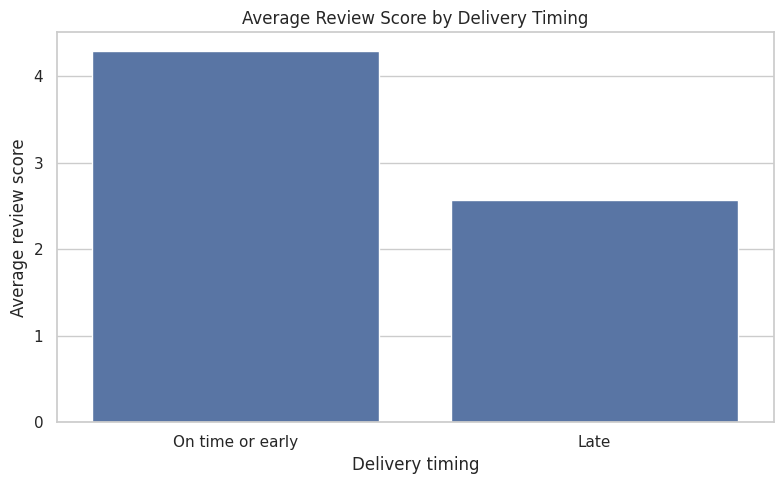

,count,mean,median
delivery_timing,,,
Late,7662,2.566562,2.0
On time or early,88168,4.294151,5.0


In [17]:
# EDA 7 — review score by delivery timing
review_delay = df[df["review_score"].notna() & df["delivery_delay_days"].notna()].copy()
review_delay["delivery_timing"] = np.where(review_delay["delivery_delay_days"] > 0, "Late", "On time or early")
summary = review_delay.groupby("delivery_timing")["review_score"].agg(["count", "mean", "median"])
plt.figure(figsize=(8,5)); sns.barplot(data=review_delay, x="delivery_timing", y="review_score", errorbar=None)
plt.title("Average Review Score by Delivery Timing"); plt.xlabel("Delivery timing"); plt.ylabel("Average review score")
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"eda_07_review_by_delivery.png", dpi=150); plt.show(); display(summary)

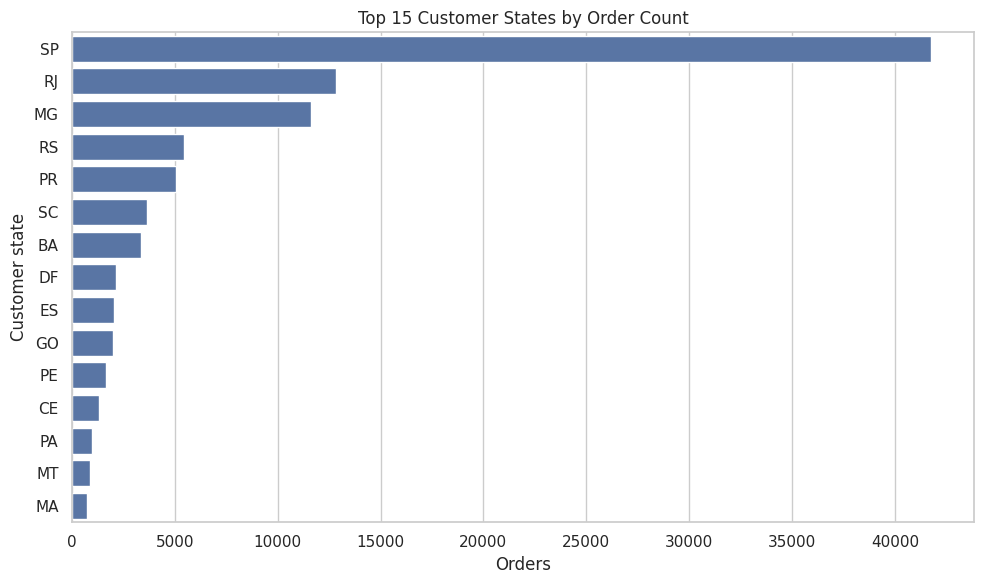

,orders
customer_state,
SP,41746
RJ,12852
MG,11635
RS,5466
PR,5045
SC,3637
BA,3380
DF,2140
ES,2033


In [18]:
# EDA 8 — top customer states by order count
state_counts = df["customer_state"].value_counts().head(15)
plt.figure(figsize=(10,6)); sns.barplot(x=state_counts.values, y=state_counts.index)
plt.title("Top 15 Customer States by Order Count"); plt.xlabel("Orders"); plt.ylabel("Customer state")
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"eda_08_customer_states.png", dpi=150); plt.show()
display(state_counts.rename("orders").to_frame())

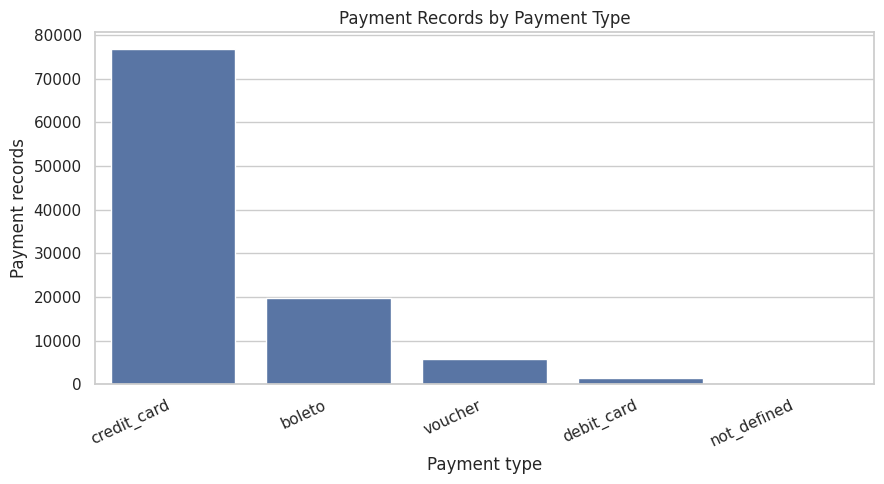

,records
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


In [19]:
# EDA 9 — payment type counts
payment_counts = payments["payment_type"].value_counts(dropna=False)
plt.figure(figsize=(9,5)); sns.barplot(x=payment_counts.index.astype(str), y=payment_counts.values)
plt.title("Payment Records by Payment Type"); plt.xlabel("Payment type"); plt.ylabel("Payment records")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.savefig(OUTPUT_DIR/"eda_09_payment_types.png", dpi=150); plt.show()
display(payment_counts.rename("records").to_frame())

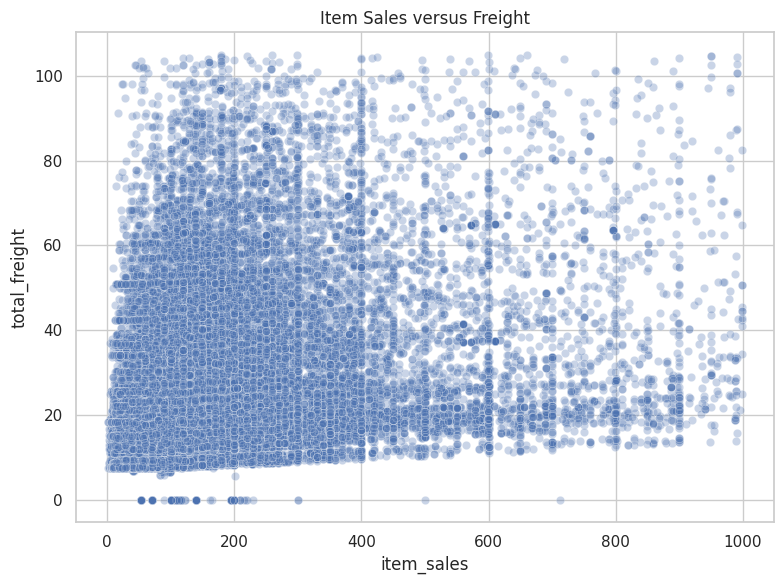

Sales/freight correlation: 0.413


In [20]:
# EDA 10 — item sales versus freight; plot clipped at 99th percentiles for readability
scatter = df[["item_sales", "total_freight"]].dropna()
scatter = scatter[(scatter.item_sales <= scatter.item_sales.quantile(.99)) & (scatter.total_freight <= scatter.total_freight.quantile(.99))]
plt.figure(figsize=(8,6)); sns.scatterplot(data=scatter, x="item_sales", y="total_freight", alpha=.3)
plt.title("Item Sales versus Freight"); plt.tight_layout(); plt.savefig(OUTPUT_DIR/"eda_10_sales_vs_freight.png", dpi=150); plt.show()
print("Sales/freight correlation:", round(df[["item_sales", "total_freight"]].corr().iloc[0,1], 3))

# 12. RFM customer segmentation with K-Means
- **Recency:** days since the customer's last purchase, measured relative to the latest purchase timestamp in this dataset.
- **Frequency:** distinct order count.
- **Monetary:** total item sales.

Use `customer_unique_id`, log-transform nonnegative RFM values, scale them, test K=2 through K=6, and use elbow plus silhouette analysis. Silhouette is calculated on a reproducible sample for speed. Final cluster names should be justified using actual cluster profiles.

In [21]:
rfm_source = df[df["customer_unique_id"].notna()].copy()
snapshot_date = rfm_source["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
customer_rfm = rfm_source.groupby("customer_unique_id").agg(
    last_purchase=("order_purchase_timestamp", "max"), frequency=("order_id", "nunique"),
    monetary=("item_sales", "sum"), customer_state=("customer_state", safe_mode)
).reset_index()
customer_rfm["recency_days"] = (snapshot_date - customer_rfm["last_purchase"]).dt.days
customer_rfm["monetary"] = customer_rfm["monetary"].fillna(0).clip(lower=0)
customer_rfm["frequency"] = customer_rfm["frequency"].fillna(0).clip(lower=0)
print("Customers:", len(customer_rfm)); display(customer_rfm[["recency_days","frequency","monetary"]].describe().T)

Customers: 96096


,count,mean,std,min,25%,50%,75%,max
recency_days,96096.0,288.735691,153.414676,1.0,164.00,269.0,398.0,773.0
frequency,96096.0,1.034809,0.214384,1.0,1.00,1.0,1.0,17.0
monetary,96096.0,141.438184,217.215904,0.0,45.99,89.0,154.0,13440.0


In [22]:
rfm_cols = ["recency_days", "frequency", "monetary"]
rfm_log = np.log1p(customer_rfm[rfm_cols].fillna(0).clip(lower=0))
rfm_scaler = StandardScaler()
rfm_scaled = rfm_scaler.fit_transform(rfm_log)
rng = np.random.RandomState(RANDOM_STATE)
sample_n = min(20000, len(customer_rfm))
sample_idx = rng.choice(len(customer_rfm), size=sample_n, replace=False)
rfm_sample = rfm_scaled[sample_idx]
k_results = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(rfm_sample)
    sil = silhouette_score(rfm_sample, labels, sample_size=min(5000, sample_n), random_state=RANDOM_STATE)
    k_results.append({"k": k, "inertia_sample": km.inertia_, "silhouette_sample": sil})
k_results_df = pd.DataFrame(k_results)
display(k_results_df); k_results_df.to_csv(OUTPUT_DIR/"kmeans_k_selection.csv", index=False)

,k,inertia_sample,silhouette_sample
0,2,40985.735090,0.713745
1,3,27575.183878,0.366688
2,4,19269.171109,0.365823
3,5,16311.474955,0.333549
4,6,14149.300470,0.320179


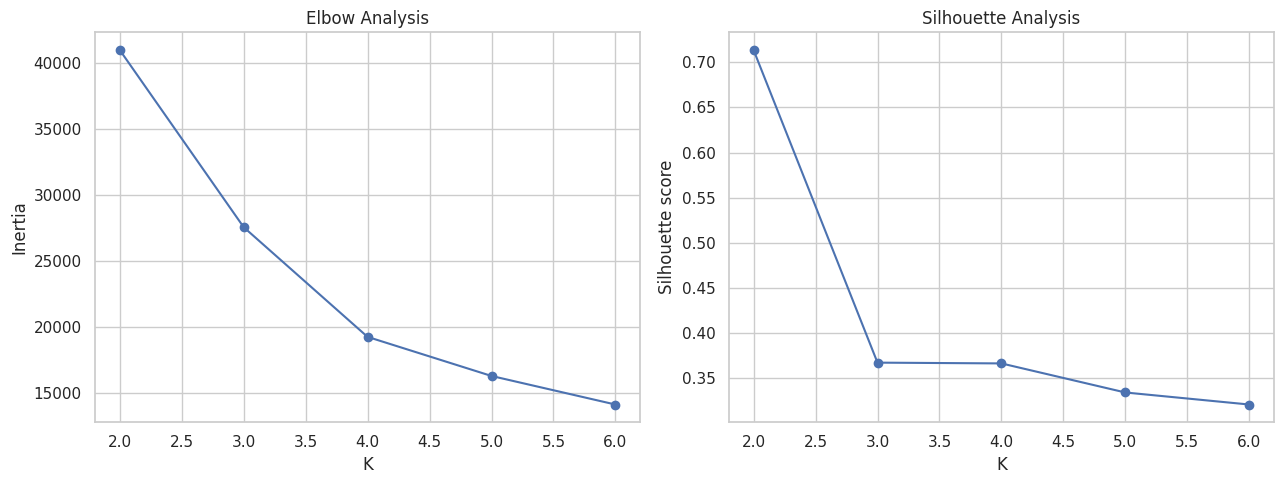

Highest sampled silhouette K: 2 — inspect both plots before finalizing.


In [23]:
fig, axes = plt.subplots(1,2,figsize=(13,5))
axes[0].plot(k_results_df.k, k_results_df.inertia_sample, marker="o"); axes[0].set_title("Elbow Analysis"); axes[0].set_xlabel("K"); axes[0].set_ylabel("Inertia")
axes[1].plot(k_results_df.k, k_results_df.silhouette_sample, marker="o"); axes[1].set_title("Silhouette Analysis"); axes[1].set_xlabel("K"); axes[1].set_ylabel("Silhouette score")
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"rfm_elbow_silhouette.png", dpi=150); plt.show()
suggested_k = int(k_results_df.loc[k_results_df.silhouette_sample.idxmax(), "k"])
print("Highest sampled silhouette K:", suggested_k, "— inspect both plots before finalizing.")

### Select final K
The next cell starts with the K that has the highest sampled silhouette score. Inspect the elbow and silhouette plots and the resulting cluster profiles. If a different K is more defensible and gives more useful groups, change `FINAL_K` and explain the reason in the report.

,cluster,customer_count,median_recency_days,mean_frequency,median_frequency,mean_monetary,median_monetary,customer_share_percent,suggested_business_label
0,0,93099,270.0,1.000000,1.0,137.625772,85.90,96.88,At-Risk Loyal Customers
1,1,2997,249.0,2.116116,2.0,259.867191,179.89,3.12,Champions / High Value


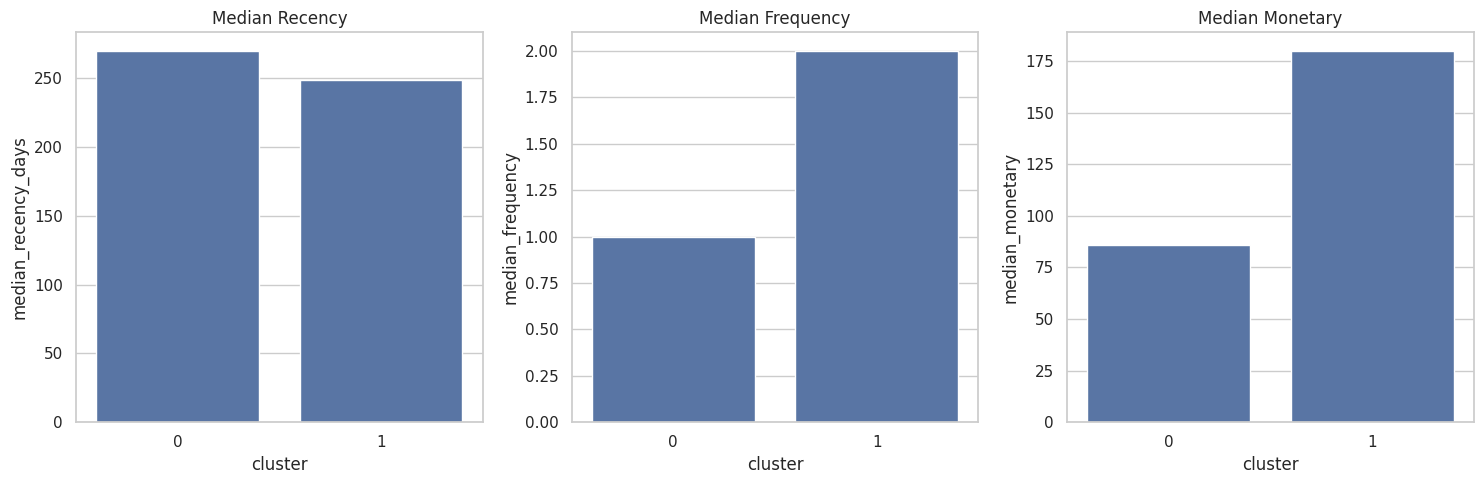

In [24]:
FINAL_K = suggested_k
kmeans_final = KMeans(n_clusters=FINAL_K, random_state=RANDOM_STATE, n_init=10)
customer_rfm["cluster"] = kmeans_final.fit_predict(rfm_scaled)
cluster_profile = customer_rfm.groupby("cluster").agg(
    customer_count=("customer_unique_id", "count"),
    median_recency_days=("recency_days", "median"),
    mean_frequency=("frequency", "mean"), median_frequency=("frequency", "median"),
    mean_monetary=("monetary", "mean"), median_monetary=("monetary", "median")
).reset_index()
cluster_profile["customer_share_percent"] = (cluster_profile.customer_count / len(customer_rfm) * 100).round(2)

overall = customer_rfm[["recency_days", "frequency", "monetary"]].median()
def label_cluster(row):
    recent = row.median_recency_days <= overall.recency_days
    frequent = row.median_frequency >= overall.frequency
    valuable = row.median_monetary >= overall.monetary
    if recent and frequent and valuable: return "Champions / High Value"
    if (not recent) and frequent: return "At-Risk Loyal Customers"
    if recent and frequent: return "Recent Frequent Customers"
    if valuable: return "High Monetary Value"
    if recent and not frequent: return "Recent / Developing"
    return "Needs Nurturing"
cluster_profile["suggested_business_label"] = cluster_profile.apply(label_cluster, axis=1)
customer_rfm = customer_rfm.merge(cluster_profile[["cluster", "suggested_business_label"]], on="cluster", validate="many_to_one")
display(cluster_profile)
cluster_profile.to_csv(OUTPUT_DIR/"customer_cluster_profiles.csv", index=False)
customer_rfm.to_csv(OUTPUT_DIR/"clustered_customer_dataset.csv", index=False)

fig, axes = plt.subplots(1,3,figsize=(15,5))
for ax, col, title in zip(axes, ["median_recency_days","median_frequency","median_monetary"], ["Median Recency", "Median Frequency", "Median Monetary"]):
    sns.barplot(data=cluster_profile, x="cluster", y=col, ax=ax); ax.set_title(title)
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"rfm_cluster_profiles.png", dpi=150); plt.show()

# 13. Predictive modeling: low review
**Target:** 1 if the order's mean review score is 1 or 2, else 0. The modeling sample includes delivered orders with a known review score. The prediction point is after delivery but before the review arrives, so delivery time/delay can be predictors. Review score, review counts, and review timestamps are not model inputs. Because the model is trained on orders with reviews, it may not generalize to orders with no review.

In [25]:
model_df = df[df["order_delivered_customer_date"].notna() & df["review_score"].notna()].copy()
model_df["low_review"] = (model_df["review_score"] <= 2).astype(int)
print("Eligible delivered orders with reviews:", len(model_df))
display(model_df.low_review.value_counts().rename(index={0:"Not low review",1:"Low review"}).to_frame("orders"))
print("Low-review percentage:", round(model_df.low_review.mean()*100, 2), "%")
if model_df.low_review.nunique() != 2: raise ValueError("Need both target classes for classification.")

Eligible delivered orders with reviews: 95830


,orders
low_review,
Not low review,83590
Low review,12240


Low-review percentage: 12.77 %


## 14. Define predictors and split the data
Identifiers and review-derived columns are excluded. Preprocessing is fitted inside each pipeline using training data only. This random stratified split is suitable for an initial assignment comparison; for production use, a time-based validation split would be a useful future improvement.

In [26]:
numeric_features = ["item_count", "item_sales", "total_freight", "unique_products", "unique_sellers", "unique_categories",
    "payment_total", "payment_installments_max", "payment_records", "delivery_days", "estimated_delivery_days",
    "delivery_delay_days", "average_item_price", "freight_share", "payment_to_item_sales_ratio", "has_multiple_items",
    "has_multiple_sellers", "purchase_month", "purchase_dayofweek", "purchase_hour", "customer_prior_order_count",
    "customer_prior_item_sales", "customer_tenure_days_at_order", "avg_product_weight_g", "avg_product_length_cm",
    "avg_product_height_cm", "avg_product_width_cm"]
categorical_features = ["customer_state", "seller_state_mode", "main_category", "payment_type_mode"]
numeric_features = [c for c in numeric_features if c in model_df.columns]
categorical_features = [c for c in categorical_features if c in model_df.columns]
X = model_df[numeric_features + categorical_features].copy()
y = model_df["low_review"].copy()
for forbidden in ["review_score", "review_records", "low_review", "review_creation_date", "review_answer_timestamp"]:
    assert forbidden not in X.columns, f"Potential leakage field: {forbidden}"
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, stratify=y, random_state=RANDOM_STATE)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Train low-review rate:", round(y_train.mean(), 4), "| Test rate:", round(y_test.mean(), 4))

Train rows: 76664 | Test rows: 19166
Train low-review rate: 0.1277 | Test rate: 0.1277


## 15. Baseline and three candidate models
The baseline predicts the majority class. Candidate models are Logistic Regression, Random Forest, and HistGradientBoosting. Dense one-hot output is used for compatibility with all three estimators. If memory is insufficient, reduce model complexity and document the adjustment.

Training Logistic Regression


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Random Forest
Training Hist Gradient Boosting


,model,accuracy,precision_low_review,recall_low_review,f1_low_review,roc_auc
0,Random Forest,0.895388,0.663228,0.367647,0.473062,0.768425
1,Hist Gradient Boosting,0.898101,0.736390,0.314951,0.441202,0.774192
2,Logistic Regression,0.749139,0.282288,0.625000,0.388917,0.741627
3,Dummy baseline,0.872274,0.000000,0.000000,0.000000,0.500000


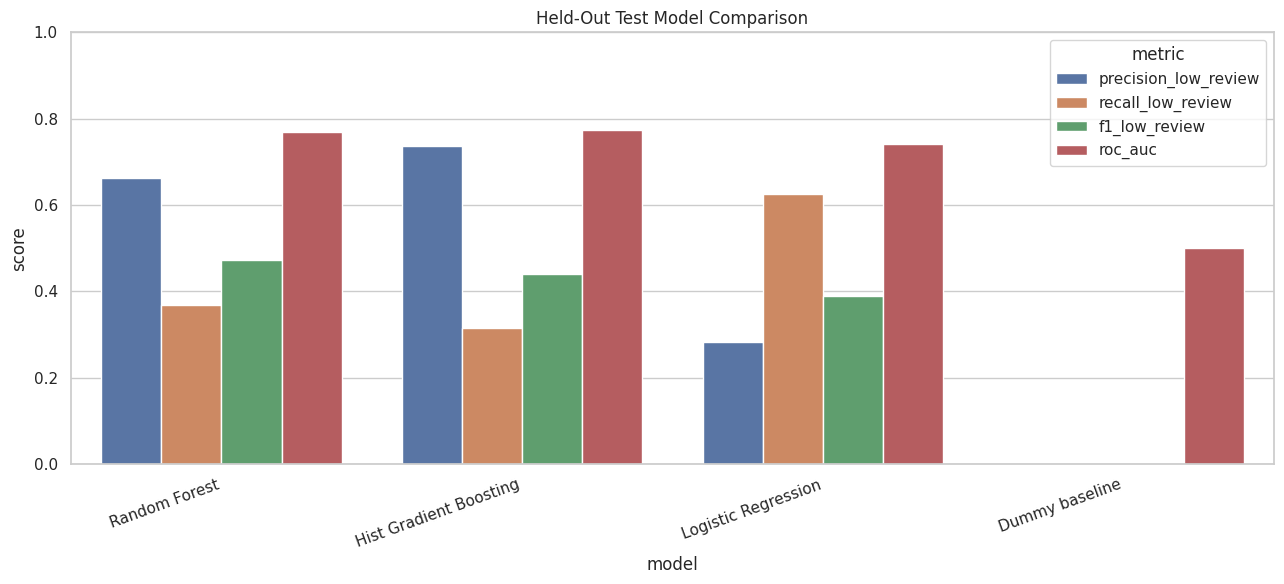

In [27]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical_features)
    ], remainder="drop", verbose_feature_names_out=False)

def metric_row(name, truth, pred, prob):
    return {"model": name, "accuracy": accuracy_score(truth, pred),
            "precision_low_review": precision_score(truth, pred, zero_division=0),
            "recall_low_review": recall_score(truth, pred, zero_division=0),
            "f1_low_review": f1_score(truth, pred, zero_division=0),
            "roc_auc": roc_auc_score(truth, prob) if len(np.unique(truth)) == 2 else np.nan}

results = []
baseline = Pipeline([("preprocessor", make_preprocessor()), ("classifier", DummyClassifier(strategy="most_frequent"))])
baseline.fit(X_train, y_train)
results.append(metric_row("Dummy baseline", y_test, baseline.predict(X_test), baseline.predict_proba(X_test)[:,1]))

candidate_models = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=120, min_samples_leaf=2, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=120, learning_rate=.1, l2_regularization=1.0, random_state=RANDOM_STATE)
}
fitted_models = {}
for name, estimator in candidate_models.items():
    print("Training", name)
    pipe = Pipeline([("preprocessor", make_preprocessor()), ("classifier", estimator)])
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    results.append(metric_row(name, y_test, pipe.predict(X_test), pipe.predict_proba(X_test)[:,1]))
model_results_df = pd.DataFrame(results).sort_values(["f1_low_review","roc_auc"], ascending=False).reset_index(drop=True)
display(model_results_df)
model_results_df.to_csv(OUTPUT_DIR/"model_training_results.csv", index=False)
plot_df = model_results_df.melt(id_vars="model", value_vars=["precision_low_review","recall_low_review","f1_low_review","roc_auc"], var_name="metric", value_name="score")
plt.figure(figsize=(13,6)); sns.barplot(data=plot_df, x="model", y="score", hue="metric")
plt.title("Held-Out Test Model Comparison"); plt.ylim(0,1); plt.xticks(rotation=20, ha="right"); plt.tight_layout()
plt.savefig(OUTPUT_DIR/"model_comparison.png", dpi=150); plt.show()

## 16. Five-fold cross-validation and hyperparameter tuning
The model with the strongest initial F1/ROC-AUC comparison is selected for tuning. F1 is the primary CV selection metric because identifying low-review orders is the focus. The test set remains reserved for final evaluation; do not repeatedly tune to it.

In [29]:
candidate_names = list(fitted_models.keys())

eligible = model_results_df[
    model_results_df["model"].isin(candidate_names)
]

if eligible.empty:
    raise ValueError("No fitted model matches model_results_df.")

initial_best_name = eligible.iloc[0]["model"]
print("Initial leading candidate:", initial_best_name)

# Faster cross-validation: 3 folds instead of 5
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

if initial_best_name == "Logistic Regression":
    estimator = LogisticRegression(
        max_iter=1500,
        random_state=RANDOM_STATE
    )
    param_grid = {
        "classifier__C": [0.1, 1.0],
        "classifier__class_weight": ["balanced", None]
    }

elif initial_best_name == "Random Forest":
    # Avoid nested parallelism; parallelize the grid search instead.
    estimator = RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1
    )
    param_grid = {
        "classifier__n_estimators": [100, 150],
        "classifier__max_depth": [None, 15],
        "classifier__min_samples_leaf": [1, 3]
    }

else:
    estimator = HistGradientBoostingClassifier(
        random_state=RANDOM_STATE
    )
    param_grid = {
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__max_iter": [80, 120]
    }

tune_pipe = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("classifier", estimator)
])

grid_search = GridSearchCV(
    estimator=tune_pipe,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=2,
    return_train_score=True,
    error_score="raise"
)

grid_search.fit(X_train, y_train)

print("Best mean CV F1:", round(grid_search.best_score_, 4))
print("Best parameters:", grid_search.best_params_)

cv_results_df = (
    pd.DataFrame(grid_search.cv_results_)
    .sort_values("rank_test_score")
)

display(cv_results_df[
    [
        "params",
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].head(10))

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
cv_results_df.to_csv(
    OUTPUT_DIR / "hyperparameter_tuning_results.csv",
    index=False
)

print("Best estimator is available as grid_search.best_estimator_.")


Initial leading candidate: Random Forest
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best mean CV F1: 0.417
Best parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 150}


,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
1,"{'classifier__max_depth': None, 'classifier__m...",0.999974,0.416996,0.004073,1
0,"{'classifier__max_depth': None, 'classifier__m...",0.999821,0.416460,0.004611,2
2,"{'classifier__max_depth': None, 'classifier__m...",0.544821,0.414482,0.005601,3
3,"{'classifier__max_depth': None, 'classifier__m...",0.544105,0.413036,0.005597,4
6,"{'classifier__max_depth': 15, 'classifier__min...",0.486041,0.402181,0.007601,5
7,"{'classifier__max_depth': 15, 'classifier__min...",0.485099,0.401479,0.007268,6
5,"{'classifier__max_depth': 15, 'classifier__min...",0.525298,0.400582,0.004736,7
4,"{'classifier__max_depth': 15, 'classifier__min...",0.526744,0.399424,0.006156,8


Best estimator is available as grid_search.best_estimator_.


## 17. Final evaluation and overfitting check
Compare training and held-out test metrics. A large train/test gap can indicate overfitting; poor scores on both can indicate underfitting. Interpret precision and recall together with the practical costs of false positives and false negatives.

,model,accuracy,precision_low_review,recall_low_review,f1_low_review,roc_auc
0,Tuned model - train,1.000000,1.000000,1.000000,1.00000,1.000000
1,Tuned model - test,0.898414,0.741562,0.314134,0.44132,0.763605


                precision    recall  f1-score   support

Not low review       0.91      0.98      0.94     16718
    Low review       0.74      0.31      0.44      2448

      accuracy                           0.90     19166
     macro avg       0.82      0.65      0.69     19166
  weighted avg       0.89      0.90      0.88     19166



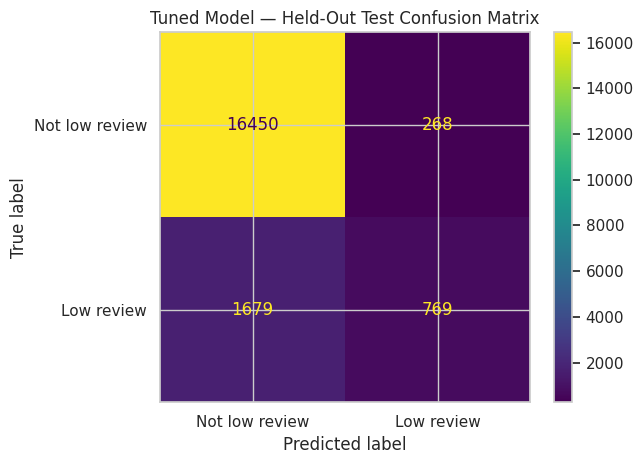

Train F1: 1.0000 | Test F1: 0.4413 | Gap: 0.5587


In [30]:
final_model = grid_search.best_estimator_
train_pred = final_model.predict(X_train); train_prob = final_model.predict_proba(X_train)[:,1]
test_pred = final_model.predict(X_test); test_prob = final_model.predict_proba(X_test)[:,1]
final_metrics = pd.DataFrame([
    metric_row("Tuned model - train", y_train, train_pred, train_prob),
    metric_row("Tuned model - test", y_test, test_pred, test_prob)
])
display(final_metrics); final_metrics.to_csv(OUTPUT_DIR/"tuned_model_train_test_metrics.csv", index=False)
print(classification_report(y_test, test_pred, target_names=["Not low review","Low review"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["Not low review","Low review"], values_format="d")
plt.title("Tuned Model — Held-Out Test Confusion Matrix"); plt.tight_layout()
plt.savefig(OUTPUT_DIR/"tuned_model_confusion_matrix.png", dpi=150); plt.show()
train_f1 = f1_score(y_train, train_pred, zero_division=0); test_f1 = f1_score(y_test, test_pred, zero_division=0)
print(f"Train F1: {train_f1:.4f} | Test F1: {test_f1:.4f} | Gap: {train_f1-test_f1:.4f}")

# 18. Monthly sales time series and forecast
Monthly sales are defined as the sum of item prices by purchase month (excluding freight). We hold out the final three months when sufficient data is available, evaluate forecasts using MAE and RMSE, then refit the selected method on all months to forecast the next three months. Forecasts are uncertain and should support planning rather than be treated as guaranteed results.

Observed months: 26 | first: 2016-09-01 00:00:00 | last: 2018-10-01 00:00:00


,monthly_item_sales
month,
2017-08-01,573971.68
2017-09-01,624401.69
2017-10-01,664219.43
2017-11-01,1010271.37
2017-12-01,743914.17
2018-01-01,950030.36
2018-02-01,844178.71
2018-03-01,983213.44
2018-04-01,996647.75


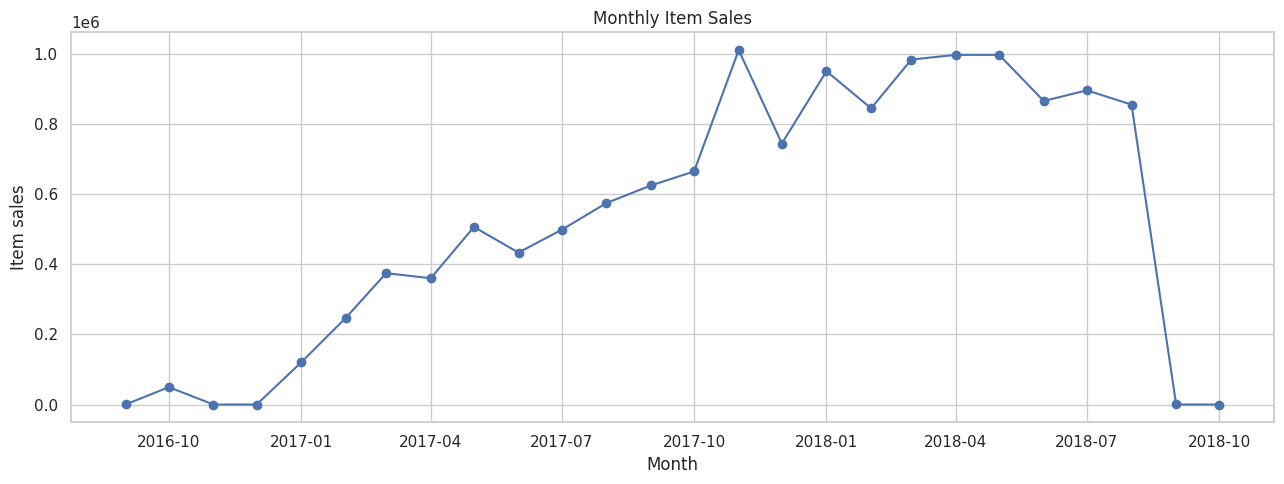

In [31]:
sales_ts = (df.assign(month=df["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp())
            .groupby("month")["item_sales"].sum().sort_index().asfreq("MS").fillna(0.0))
sales_ts.name = "monthly_item_sales"
print("Observed months:", len(sales_ts), "| first:", sales_ts.index.min(), "| last:", sales_ts.index.max())
display(sales_ts.tail(15).to_frame())
plt.figure(figsize=(13,5)); plt.plot(sales_ts.index, sales_ts.values, marker="o")
plt.title("Monthly Item Sales"); plt.xlabel("Month"); plt.ylabel("Item sales"); plt.tight_layout()
plt.savefig(OUTPUT_DIR/"monthly_sales_time_series.png", dpi=150); plt.show()
if len(sales_ts) < 8: raise ValueError("Too few monthly observations for a meaningful holdout forecast.")

,method,train_months,test_months,MAE,RMSE
0,Exponential Smoothing,23,3,674829.051448,784014.511791


,month,actual_sales,forecast_sales
0,2018-08-01,854686.33,965104.143001
1,2018-09-01,145.00,959772.828115
2,2018-10-01,0.00,954441.513230


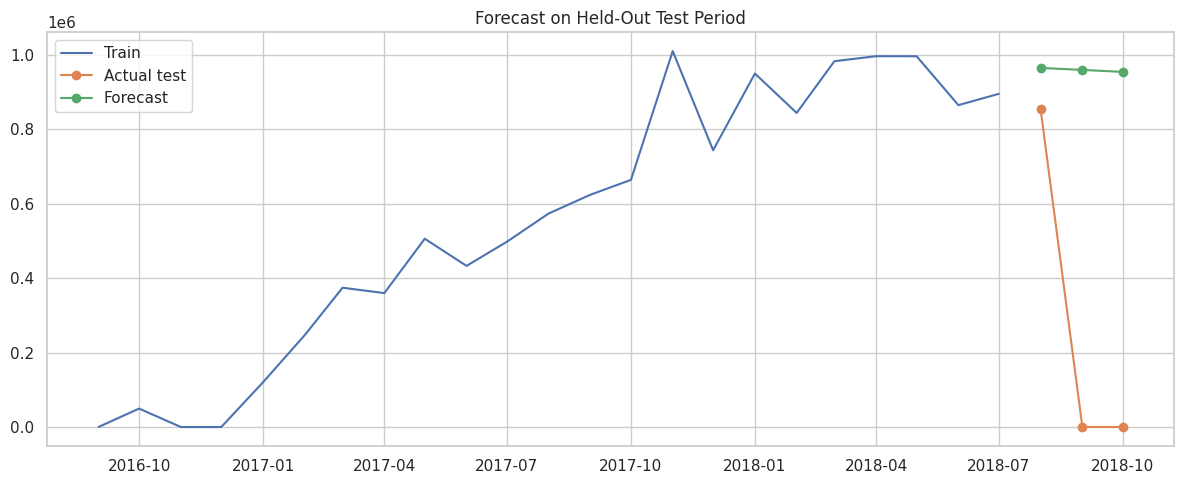

In [32]:
test_months = 3 if len(sales_ts) >= 15 else max(1, round(len(sales_ts)*.2))
train_ts, test_ts = sales_ts.iloc[:-test_months], sales_ts.iloc[-test_months:]
def fit_forecaster(series):
    if len(series) >= 24:
        return ExponentialSmoothing(series, trend="add", seasonal="add", seasonal_periods=12, initialization_method="estimated").fit(optimized=True)
    if len(series) >= 3:
        return ExponentialSmoothing(series, trend="add", seasonal=None, initialization_method="estimated").fit(optimized=True)
    return None
model_ts = fit_forecaster(train_ts)
if model_ts is None:
    holdout_forecast = pd.Series([train_ts.iloc[-1]]*len(test_ts), index=test_ts.index)
    forecast_method = "Last-value naive"
else:
    holdout_forecast = pd.Series(np.asarray(model_ts.forecast(len(test_ts))), index=test_ts.index)
    forecast_method = "Exponential Smoothing"
mae = mean_absolute_error(test_ts, holdout_forecast)
rmse = np.sqrt(mean_squared_error(test_ts, holdout_forecast))
forecast_metrics = pd.DataFrame([{"method": forecast_method, "train_months": len(train_ts), "test_months": len(test_ts), "MAE": mae, "RMSE": rmse}])
display(forecast_metrics); forecast_metrics.to_csv(OUTPUT_DIR/"forecast_evaluation_metrics.csv", index=False)
forecast_test_df = pd.DataFrame({"month": test_ts.index, "actual_sales": test_ts.values, "forecast_sales": holdout_forecast.values})
display(forecast_test_df); forecast_test_df.to_csv(OUTPUT_DIR/"forecast_test_period.csv", index=False)
plt.figure(figsize=(12,5)); plt.plot(train_ts.index, train_ts.values, label="Train")
plt.plot(test_ts.index, test_ts.values, marker="o", label="Actual test")
plt.plot(holdout_forecast.index, holdout_forecast.values, marker="o", label="Forecast")
plt.title("Forecast on Held-Out Test Period"); plt.legend(); plt.tight_layout()
plt.savefig(OUTPUT_DIR/"forecast_test_comparison.png", dpi=150); plt.show()

,month,forecast_item_sales,method
0,2018-11-01,-232544.068155,Exponential Smoothing
1,2018-12-01,-749528.585276,Exponential Smoothing
2,2019-01-01,-993648.507527,Exponential Smoothing


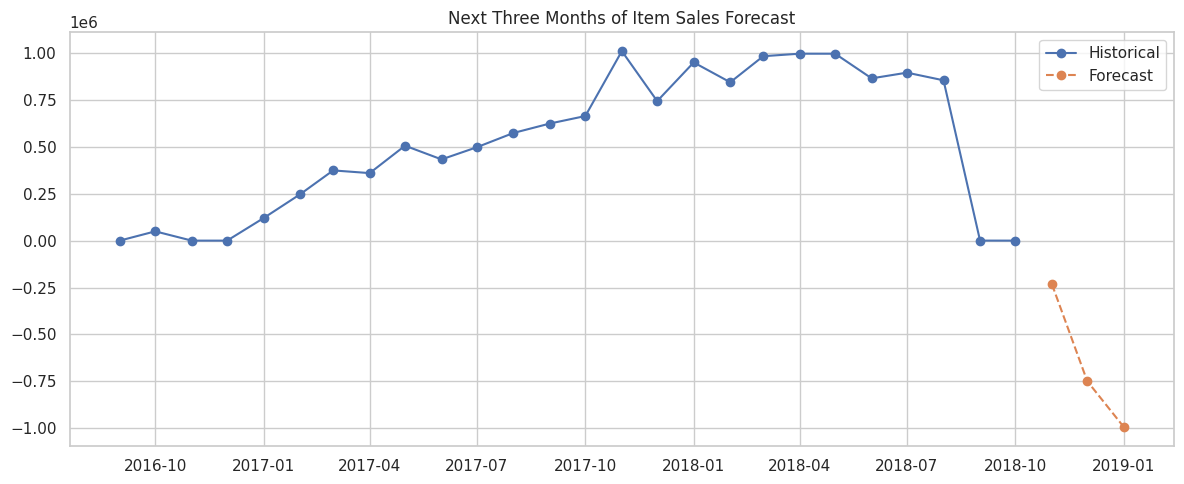

In [33]:
# Refit on all history and forecast the next three months.
horizon = 3
full_ts_model = fit_forecaster(sales_ts)
if full_ts_model is None:
    future_values = np.repeat(sales_ts.iloc[-1], horizon); future_method = "Last-value naive"
else:
    future_values = np.asarray(full_ts_model.forecast(horizon)); future_method = "Exponential Smoothing"
future_index = pd.date_range(sales_ts.index.max() + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
future_forecast_df = pd.DataFrame({"month": future_index, "forecast_item_sales": future_values, "method": future_method})
display(future_forecast_df); future_forecast_df.to_csv(OUTPUT_DIR/"future_sales_forecast.csv", index=False)
plt.figure(figsize=(12,5)); plt.plot(sales_ts.index, sales_ts.values, marker="o", label="Historical")
plt.plot(future_index, future_values, marker="o", linestyle="--", label="Forecast")
plt.title("Next Three Months of Item Sales Forecast"); plt.legend(); plt.tight_layout()
plt.savefig(OUTPUT_DIR/"future_sales_forecast.png", dpi=150); plt.show()